In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras.utils import to_categorical
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
train_raw = tfds.load(
    "tf_flowers",
    split="train[:70%]",
    as_supervised=True
)

test_raw = tfds.load(
    "tf_flowers",
    split="train[70%:]",
    as_supervised=True
)

train_images, train_label_list = [], []
test_images, test_label_list = [], []

for image, label in train_raw:
    image = tf.image.resize(image, (150, 150))
    train_images.append(image.numpy())
    train_label_list.append(int(label.numpy()))

for image, label in test_raw:
    image = tf.image.resize(image, (150, 150))
    test_images.append(image.numpy())
    test_label_list.append(int(label.numpy()))

train_ds = np.asarray(train_images, dtype=np.float32)
test_ds = np.asarray(test_images, dtype=np.float32)

train_labels = np.asarray(train_label_list)
test_labels = np.asarray(test_label_list)

print("Training images:", train_ds.shape)
print("Test images:", test_ds.shape)

Training images: (2569, 150, 150, 3)
Test images: (1101, 150, 150, 3)


In [21]:
## check existing image size
train_ds[0].shape

TensorShape([150, 150, 3])

In [4]:
## Resizing images
train_ds = tf.image.resize(train_ds, (150, 150))
test_ds = tf.image.resize(test_ds, (150, 150))

In [5]:
print(train_labels[:20])

[2 3 3 4 3 0 0 0 0 1 3 2 4 1 2 1 1 2 3 3]


In [6]:
train_labels = to_categorical(train_labels, num_classes=5)
test_labels = to_categorical(test_labels, num_classes=5)

print("Training labels:", train_labels.shape)
print("Test labels:", test_labels.shape)

Training labels: (2569, 5)
Test labels: (1101, 5)


In [7]:
train_labels[0]

array([0., 0., 1., 0., 0.])

In [8]:
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

In [9]:
train_ds[0].shape

TensorShape([150, 150, 3])

In [10]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

print("VGG16 loaded.")

VGG16 loaded.


In [11]:
## will not train base mode
# Freeze Parameters in model's lower convolutional layers
base_model.trainable = False

In [12]:
train_ds = preprocess_input(train_ds)
test_ds = preprocess_input(test_ds)

print("Preprocessing complete.")

Preprocessing complete.


In [13]:
## model details
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 150, 150, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 150, 150, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 75, 75, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 75, 75, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 75, 75, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 37, 37, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 37, 37, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 18, 18, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 18, 18, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 9, 9, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 4, 4, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

**Add custom classifier with two dense layers of trainable parameters to model**

In [14]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(5, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 50)                  │         409,650 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 20)                  │           1,020 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             105 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

**Train classifier layers on training data available for task**

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
es = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=5,
    restore_best_weights=True
)

In [17]:
history = model.fit(
    train_ds,
    train_labels,
    epochs=3,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es]
)

Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 260s 4s/step - accuracy: 0.6380 - loss: 1.7764 - val_accuracy: 0.6887 - val_loss: 1.0061
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 8664s 135s/step - accuracy: 0.8535 - loss: 0.4661 - val_accuracy: 0.7568 - val_loss: 0.9461
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 264s 4s/step - accuracy: 0.9309 - loss: 0.2324 - val_accuracy: 0.7821 - val_loss: 0.7690


In [18]:
loss, accuracy = model.evaluate(test_ds, test_labels, verbose=1)

print("Loss:", loss)
print("Accuracy:", accuracy)

35/35 ━━━━━━━━━━━━━━━━━━━━ 111s 3s/step - accuracy: 0.7766 - loss: 0.8196
Loss: 0.8195977210998535
Accuracy: 0.776566743850708


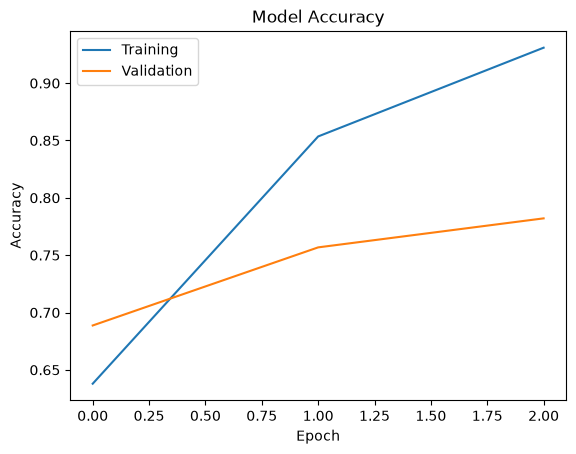

In [19]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.show()

In [20]:
y_pred = model.predict(test_ds, batch_size=32, verbose=1)
y_classes = np.argmax(y_pred, axis=1)
actual_classes = np.argmax(test_labels, axis=1)

print("Predicted labels:", y_classes[:10])
print("Actual labels:", actual_classes[:10])

35/35 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step
Predicted labels: [4 3 1 3 0 3 0 3 1 0]
Actual labels: [4 0 1 3 0 3 0 3 1 3]


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = train_ds.class_names

for images, labels in test_ds.take(1):

    predictions = model.predict(images)

    for i in range(5):
        predicted_label = np.argmax(predictions[i])
        actual_label = labels[i].numpy()

        plt.figure(figsize=(4, 4))
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Predicted: {class_names[predicted_label]}\n"
            f"Actual: {class_names[actual_label]}"
        )
        plt.axis("off")
        plt.show()

        print("Predicted flower:", class_names[predicted_label])
        print("Actual flower:", class_names[actual_label])
        print("Confidence:", round(float(np.max(predictions[i])) * 100, 2), "%")
        print("-" * 40)

AttributeError: 'tensorflow.python.framework.ops.EagerTensor' object has no attribute 'class_names'